In [120]:
import requests

url = "https://luftdaten.umweltbundesamt.de/api-proxy/meta/json"
params = {
    "use": "airquality",
    "date_from": "2025-06-01",
    "date_to": "2026-06-30",
    "time_from": 1,
    "time_to": 24,
    "lang": "de",
}

response = requests.get(url, params=params, timeout=30)
print(response.status_code)
meta = response.json()
print(type(meta))
print(list(meta.keys()))

200
<class 'dict'>
['components', 'scopes', 'limits', 'stations', 'networks', 'request', 'meta']


In [121]:
print(len(meta))

7


In [122]:
response.url

'https://luftdaten.umweltbundesamt.de/api-proxy/meta/json?use=airquality&date_from=2025-06-01&date_to=2026-06-30&time_from=1&time_to=24&lang=de'

In [123]:
stations=meta["stations"]
print(type(stations))
print(len(stations))
first=list(stations.items())[0] if isinstance (stations, dict) else stations[0]
print(first)

<class 'dict'>
431
('21', ['21', 'DEBB021', 'Potsdam-Zentrum', 'Potsdam', 'PDBA', '2009-04-15', None, '13.0602', '52.4014', '4', '1', '1', 'BB', 'Brandenburg', 'städtisches Gebiet', 'städtisch', 'Hintergrund', 'Am Bassinplatz', '', '14467'])


In [124]:
stations=meta["stations"]
munich=[s for s in stations.values () if "München" in s]
print (len(munich))
for s in munich:
    print(s)

4
['471', 'DEBY037', 'München/Stachus', 'München', '', '1978-01-01', None, '11.5649', '48.1373', '2', '1', '3', 'BY', 'Bayern', 'städtisches Gebiet', 'städtisch', 'Verkehr', 'Sonnenstraße', '', '80335']
['473', 'DEBY039', 'München/Lothstraße', 'München', '', '1978-01-01', None, '11.5547', '48.1545', '2', '1', '1', 'BY', 'Bayern', 'städtisches Gebiet', 'städtisch', 'Hintergrund', 'Lothstraße', '62', '80335']
['535', 'DEBY115', 'München/Landshuter Allee', 'München', '', '2004-07-01', None, '11.5365', '48.1496', '2', '1', '3', 'BY', 'Bayern', 'städtisches Gebiet', 'städtisch', 'Verkehr', 'Landshuter Allee', '31', '80637']
['609', 'DEBY189', 'München/Allach', 'München', '', '2014-01-28', None, '11.4645', '48.1817', '2', '2', '1', 'BY', 'Bayern', 'vorstädtisches Gebiet', 'vorstädtisch', 'Hintergrund', 'Allacher Straße', '305', '80999']


In [125]:
url = "https://luftdaten.umweltbundesamt.de/api-proxy/measures/json"
params = {
    "date_from": "2022-08-01",
    "date_to": "2022-08-01",
    "time_from": 1,
    "time_to": 24,
    "station": "DENW207",
    "component": 5,
}
r = requests.get(url, params=params, timeout=30)
print(r.status_code)
data = r.json()
print(type(data))
print(str(data)[:800])

200
<class 'dict'>
{'request': {'component': '5', 'station': '1250', 'date_from': '2022-08-01', 'date_to': '2022-08-01', 'time_from': '01:00:00', 'time_to': '24:00:00', 'recent': False, 'index': 'id', 'lang': 'en', 'datetime_from': '2022-08-01 00:00:00', 'datetime_to': '2022-08-01 23:00:00'}, 'indices': {'data': {'station id': {'date start': ['component id', 'scope id', 'value', 'date end', 'index']}}}, 'data': {'1250': {'2022-08-01 00:00:00': [5, 2, 5, '2022-08-01 01:00:00', '0'], '2022-08-01 01:00:00': [5, 2, 8, '2022-08-01 02:00:00', '0'], '2022-08-01 02:00:00': [5, 2, 5, '2022-08-01 03:00:00', '0'], '2022-08-01 03:00:00': [5, 2, 7, '2022-08-01 04:00:00', '0'], '2022-08-01 04:00:00': [5, 2, 10, '2022-08-01 05:00:00', '0'], '2022-08-01 05:00:00': [5, 2, 17, '2022-08-01 06:00:00', '0'], '2022-08-01 06:00:00


In [126]:
import requests
import pandas as pd

url = "https://luftdaten.umweltbundesamt.de/api-proxy/measures/json"
params = {
    "date_from": "2025-01-13",
    "date_to": "2025-01-19",
    "time_from": 1,
    "time_to": 24,
    "station": "DEBY037",
    "component": 5,
    "scope": 2,
}
r = requests.get(url, params=params, timeout=30)
print(r.status_code)
records = r.json()["data"]["471"]

rows = []
for date_start, v in records.items():
    rows.append({"date_start": date_start, "value": v[2], "date_end": v[3]})

df = pd.DataFrame(rows)
print(df.shape)
print(df.head())

200
(168, 3)
            date_start  value             date_end
0  2025-01-13 00:00:00     22  2025-01-13 01:00:00
1  2025-01-13 01:00:00     22  2025-01-13 02:00:00
2  2025-01-13 02:00:00     17  2025-01-13 03:00:00
3  2025-01-13 03:00:00     20  2025-01-13 04:00:00
4  2025-01-13 04:00:00     22  2025-01-13 05:00:00


In [127]:
station_codes = ["DEBY037", "DEBY039", "DEBY115", "DEBY189"]
components = {5: "NO2", 1: "PM10"}

rows = []
for code in station_codes:
    for comp_id, comp_name in components.items():
        params = {
            "date_from": "2025-01-13",
            "date_to": "2025-01-19",
            "time_from": 1,
            "time_to": 24,
            "station": code,
            "component": comp_id,
            "scope": 2,
        }
        r = requests.get(url, params=params, timeout=30)
        data = r.json().get("data", {})
        for station_id, records in data.items():
            for date_start, v in records.items():
                rows.append({
                    "station_code": code,
                    "pollutant": comp_name,
                    "date_start": date_start,
                    "value": v[2],
                    "date_end": v[3],
                })

air = pd.DataFrame(rows)
print(air.shape)
print(air.groupby(["station_code", "pollutant"]).size())

(1176, 5)
station_code  pollutant
DEBY037       NO2          168
              PM10         168
DEBY039       NO2          168
              PM10         168
DEBY115       NO2          168
              PM10         168
DEBY189       NO2          168
dtype: int64


In [128]:
print(air.groupby(["station_code", "pollutant"])["value"].describe().round(1))

                        count  mean   std   min   25%   50%   75%   max
station_code pollutant                                                 
DEBY037      NO2        168.0  29.7  11.3  12.0  21.0  27.5  37.2  56.0
             PM10       168.0  23.0   8.8  10.0  15.0  21.0  28.2  49.0
DEBY039      NO2        168.0  24.0  10.9   9.0  15.0  21.5  31.2  55.0
             PM10       168.0  19.3   7.4   8.0  13.0  19.0  24.0  38.0
DEBY115      NO2        168.0  33.8  13.2  13.0  24.0  31.0  42.0  67.0
             PM10       168.0  22.6   9.4   9.0  15.0  21.0  29.2  50.0
DEBY189      NO2        168.0  27.7  10.0  11.0  20.0  26.0  34.0  53.0


In [129]:
r = requests.get(
    url,
    params={
        "date_from": "2024-01-01",
        "date_to": "2024-01-31",
        "time_from": 1,
        "time_to": 24,
        "station": "DEBY189",
        "component": 1,
        "scope": 2,
    },
    timeout=30,
)
print(r.status_code)
print(len(r.json()["data"]))

200
0


In [130]:
print(meta["components"])

{'1': ['1', 'PM10', 'PM₁₀', 'µg/m³', 'Feinstaub'], '2': ['2', 'CO', 'CO', 'mg/m³', 'Kohlenmonoxid'], '3': ['3', 'O3', 'O₃', 'µg/m³', 'Ozon'], '4': ['4', 'SO2', 'SO₂', 'µg/m³', 'Schwefeldioxid'], '5': ['5', 'NO2', 'NO₂', 'µg/m³', 'Stickstoffdioxid'], '6': ['6', 'PM10PB', 'Pb', 'µg/m³', 'Blei im Feinstaub'], '7': ['7', 'PM10BAP', 'BaP', 'ng/m³', 'Benzo(a)pyren im Feinstaub'], '8': ['8', 'CHB', 'C₆H₆', 'µg/m³', 'Benzol'], '9': ['9', 'PM2', 'PM₂,₅', 'µg/m³', 'Feinstaub'], '10': ['10', 'PM10AS', 'As', 'ng/m³', 'Arsen im Feinstaub'], '11': ['11', 'PM10CD', 'Cd', 'ng/m³', 'Cadmium im Feinstaub'], '12': ['12', 'PM10NI', 'Ni', 'ng/m³', 'Nickel im Feinstaub']}


In [131]:
name = "Stachus"
no2 = 29.7
print(name,no2)

Stachus 29.7


In [132]:
values =[22,22,17,20]

In [133]:
print(values[0])

22


In [134]:
print(len(values))
for v in values:
    print(v)

4
22
22
17
20


In [135]:
station_names = ["Stachus", "Lothstrasse", "Landshuter Allee", "Allach"]
print(station_names[0])
print(len(station_names))

mean_no2 = {
    "Stachus": 29.7,
    "Lothstrasse": 24.0,
    "Landshuter Allee": 33.8,
    "Allach": 27.7,
}
print(mean_no2["Allach"])

for s in station_names:
    print(s, mean_no2[s])

Stachus
4
27.7
Stachus 29.7
Lothstrasse 24.0
Landshuter Allee 33.8
Allach 27.7


In [136]:
records = {
    "2025-01-13 00:00:00": [5, 2, 22, "2025-01-13 01:00:00", "0"],
    "2025-01-13 01:00:00": [5, 2, 22, "2025-01-13 02:00:00", "0"],
}

for date_start, v in records.items():
    print(date_start, v[2])

2025-01-13 00:00:00 22
2025-01-13 01:00:00 22


In [137]:
records = {
    "2025-01-13 00:00:00": [5, 2, 22, "2025-01-13 01:00:00", "0"],
    "2025-01-13 01:00:00": [5, 2, 22, "2025-01-13 02:00:00", "0"],
}

for date_start, v in records.items():
    print(date_start, v[3])

2025-01-13 00:00:00 2025-01-13 01:00:00
2025-01-13 01:00:00 2025-01-13 02:00:00


In [138]:
dwd_url = (
    "https://opendata.dwd.de/climate_environment/CDC/observations_germany/"
    "climate/hourly/air_temperature/historical/"
    "TU_Stundenwerte_Beschreibung_Stationen.txt"
)
resp = requests.get(dwd_url, timeout=30)
print(resp.status_code)

lines = resp.content.decode("latin-1").splitlines()
print(len(lines))
for line in lines[:3]:
    print(line)
print("---")
for line in lines:
    if "München" in line or "Muenchen" in line:
        print(line)

200
670
Stations_id von_datum bis_datum Stationshoehe geoBreite geoLaenge Stationsname Bundesland Abgabe
----------- --------- --------- ------------- --------- --------- ----------------------------------------- ---------- ------
00003 19500401 20110331            202     50.7827    6.0941 Aachen                                   Nordrhein-Westfalen                      Frei                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                              

In [139]:
base = (
    "https://opendata.dwd.de/climate_environment/CDC/observations_germany/"
    "climate/hourly/air_temperature/"
)

for folder in ["historical", "recent"]:
    page = requests.get(base + folder + "/", timeout=60)
    print(folder, page.status_code)
    for line in page.text.splitlines():
        if "TU_03379" in line:
            print(line)

historical 200
<a href="stundenwerte_TU_03379_19970701_20251231_hist.zip">stundenwerte_TU_03379_19970701_20251231_hist.zip</a>   10-Jun-2026 23:05:15             1364664
recent 200
<a href="stundenwerte_TU_03379_akt.zip">stundenwerte_TU_03379_akt.zip</a>                      19-Nov-2026 08:45:08               81475


In [140]:
import io
import zipfile

zip_url = base + "historical/stundenwerte_TU_03379_19970701_20251231_hist.zip"
z = requests.get(zip_url, timeout=60)
print(z.status_code, len(z.content))

if z.status_code == 200:
    zf = zipfile.ZipFile(io.BytesIO(z.content))
    print(zf.namelist())

200 1364664
['Metadaten_Stationsname_Betreibername_03379.html', 'Metadaten_Stationsname_Betreibername_03379.txt', 'Metadaten_Parameter_tu_stunde_03379.html', 'Metadaten_Parameter_tu_stunde_03379.txt', 'Metadaten_Geraete_Lufttemperatur_03379.html', 'Metadaten_Geraete_Lufttemperatur_03379.txt', 'Metadaten_Geraete_Rel_Feuchte_03379.html', 'Metadaten_Geraete_Rel_Feuchte_03379.txt', 'Metadaten_Geographie_03379.txt', 'Metadaten_Fehldaten_03379_19970701_20251231.html', 'Metadaten_Fehldaten_03379_19970701_20251231.txt', 'Metadaten_Fehlwerte_03379_19970701_20251231.txt', 'produkt_tu_stunde_19970701_20251231_03379.txt']


In [141]:
data_name = "produkt_tu_stunde_19970701_20251231_03379.txt"
text = zf.read(data_name).decode("latin-1")
lines = text.splitlines()
print(len(lines))
for line in lines[:5]:
    print(line)
print("---")
for line in lines[-2:]:
    print(line)

247409
STATIONS_ID;MESS_DATUM;QN_9;TT_TU;RF_TU;eor
       3379;1997070101;   10;  12.8;  80.0;eor
       3379;1997070102;   10;  12.6;  81.0;eor
       3379;1997070103;   10;  12.4;  81.0;eor
       3379;1997070104;   10;  12.4;  82.0;eor
---
       3379;2025123122;    3;  -3.4;  64.0;eor
       3379;2025123123;    3;  -3.6;  63.0;eor


In [142]:
meta_name = "Metadaten_Parameter_tu_stunde_03379.txt"
print(zf.read(meta_name).decode("latin-1")[:1500])

Stations_ID;Von_Datum;Bis_Datum;Stationsname;Parameter;Parameterbeschreibung;Einheit;Datenquelle (Strukturversion=SV);Zusatz-Info;Besonderheiten;Literaturhinweis;eor;
3379;19970701;19981029;München-Stadt;RF_TU;relative Feuchte;%;Daten der Temperatur und relativen Feuchte (Stundenwerte) von automatischen Stationen der 1. Generation (MIRIAM/AFMS2, ESAU-Daten);Stundenwerte in UTC;;;eor;
3379;19981029;19981102;München-Stadt;RF_TU;relative Feuchte;%;Daten der Temperatur und relativen Feuchte (Stundenwerte) aus analogen Registrierungen (Thermohygrograph);Stundenwerte in MEZ;;;eor;
3379;19981102;20010401;München-Stadt;RF_TU;relative Feuchte;%;Daten der Temperatur und relativen Feuchte (Stundenwerte) von automatischen Stationen der 1. Generation (MIRIAM/AFMS2, ESAU-Daten);Stundenwerte in UTC;;;eor;
3379;20010401;20260418;München-Stadt;RF_TU;relative Feuchte;%;Daten der Temperatur und relativen Feuchte (Stundenwerte) generiert aus SYNOP-Meldungen (nach dem 01.04.2001);Stundenwerte in UTC;;;eor;

In [143]:
test = requests.get(
    "https://luftdaten.umweltbundesamt.de/api-proxy/measures/json",
    params={
        "date_from": "2025-01-13",
        "date_to": "2025-01-13",
        "time_from": 1,
        "time_to": 24,
        "station": "DEBY037",
        "component": 5,
        "scope": 2,
    },
    timeout=30,
)
print(test.json()["meta"])

{'source': 'Source: Umweltbundesamt (German Federal Environment Agency), https://www.umweltbundesamt.de/daten/luft/luftdaten. All times are indicated in the time zone valid at the measurement time (CET or CEST).', 'cachedAt': '2026-11-19T11:52:01+01:00', 'uri': '/api/air-data/v4/measures/json?component=5&date_from=2025-01-13&date_to=2025-01-13&scope=2&station=DEBY037&time_from=1&time_to=24', 'lang': 'en'}


In [144]:
fehl = "Metadaten_Fehlwerte_03379_19970701_20251231.txt"
print(zf.read(fehl).decode("latin-1")[:1500])

Stations_ID;Stations_Name;Parameter;Von_Datum;Bis_Datum;Anzahl_Fehlwerte;Beschreibung;eor;                                                                                                              
3379;München-Stadt;TT_TU;01.07.1997-08:00;01.07.1997-08:00;1;;eor;                                                                                                                                      
3379;München-Stadt;TT_TU;08.07.1997-17:00;08.07.1997-17:00;1;;eor;                                                                                                                                      
3379;München-Stadt;TT_TU;08.07.1997-23:00;08.07.1997-23:00;1;;eor;                                                                                                                                      
3379;München-Stadt;TT_TU;10.07.1997-01:00;10.07.1997-04:00;4;;eor;                                                                                                                                  

In [145]:
import pandas as pd

temp = pd.read_csv(
    io.BytesIO(zf.read(data_name)),
    sep=";",
    skipinitialspace=True,
)
print(temp.shape)
print(temp.dtypes)
print(temp.head(3))
print(temp[["TT_TU", "RF_TU"]].describe())

(247408, 6)
STATIONS_ID      int64
MESS_DATUM       int64
QN_9             int64
TT_TU          float64
RF_TU          float64
eor                str
dtype: object
   STATIONS_ID  MESS_DATUM  QN_9  TT_TU  RF_TU  eor
0         3379  1997070101    10   12.8   80.0  eor
1         3379  1997070102    10   12.6   81.0  eor
2         3379  1997070103    10   12.4   81.0  eor
               TT_TU          RF_TU
count  247408.000000  247408.000000
mean        9.963426      72.610457
std        21.835894      31.230883
min      -999.000000    -999.000000
25%         4.000000      60.000000
50%        10.300000      77.000000
75%        16.400000      89.000000
max        36.700000     100.000000


In [146]:
temp["time_utc"] = pd.to_datetime(
    temp["MESS_DATUM"].astype(str), format="%Y%m%d%H", utc=True
)
temp["time_local"] = temp["time_utc"].dt.tz_convert("Europe/Berlin")

t2025 = temp[temp["time_utc"].dt.year == 2025]
print(len(t2025))
print(t2025[["time_utc", "time_local", "TT_TU"]].head(3))
print(t2025["TT_TU"].isna().sum())

8760
                        time_utc                time_local  TT_TU
238648 2025-01-01 00:00:00+00:00 2025-01-01 01:00:00+01:00   -1.1
238649 2025-01-01 01:00:00+00:00 2025-01-01 02:00:00+01:00   -2.0
238650 2025-01-01 02:00:00+00:00 2025-01-01 03:00:00+01:00   -2.4
0


In [147]:
air_url = "https://luftdaten.umweltbundesamt.de/api-proxy/measures/json"
params = {
    "date_from": "2025-01-01",
    "date_to": "2025-12-31",
    "time_from": 1,
    "time_to": 24,
    "station": "DEBY037",
    "component": 5,
    "scope": 2,
}
r = requests.get(air_url, params=params, timeout=120)
print(r.status_code)
records = r.json()["data"]["471"]
print(len(records))

200
8760


In [148]:
import numpy as np

cols = ["TT_TU", "RF_TU"]
print((temp[cols] == -999).sum())

temp_clean = temp.copy()
temp_clean[cols] = temp_clean[cols].replace(-999, np.nan)
print(temp_clean[cols].describe())

t2025 = temp_clean[temp_clean["time_utc"].dt.year == 2025]
print(len(t2025))
print(t2025["TT_TU"].isna().sum())

TT_TU     99
RF_TU    137
dtype: int64
               TT_TU          RF_TU
count  247309.000000  247271.000000
mean       10.367323      73.204181
std         8.325563      18.420449
min       -16.200000      10.000000
25%         4.000000      60.000000
50%        10.300000      77.000000
75%        16.400000      89.000000
max        36.700000     100.000000
8760
72


In [149]:
import time

station_codes = ["DEBY037", "DEBY039", "DEBY115", "DEBY189"]
components = {5: "NO2", 1: "PM10"}

rows = []
for code in station_codes:
    for comp_id, comp_name in components.items():
        params = {
            "date_from": "2025-01-01",
            "date_to": "2025-12-31",
            "time_from": 1,
            "time_to": 24,
            "station": code,
            "component": comp_id,
            "scope": 2,
        }
        r = requests.get(air_url, params=params, timeout=120)
        print(code, comp_name, r.status_code)
        data = r.json().get("data", {})
        for station_id, records in data.items():
            for date_start, v in records.items():
                rows.append({
                    "station_code": code,
                    "pollutant": comp_name,
                    "date_start": date_start,
                    "value": v[2],
                    "date_end": v[3],
                })
        time.sleep(1)

air2025 = pd.DataFrame(rows)
print(air2025.shape)
print(air2025.groupby(["station_code", "pollutant"]).size())

DEBY037 NO2 200
DEBY037 PM10 200
DEBY039 NO2 200
DEBY039 PM10 200
DEBY115 NO2 200
DEBY115 PM10 200
DEBY189 NO2 200
DEBY189 PM10 200
(61320, 5)
station_code  pollutant
DEBY037       NO2          8760
              PM10         8760
DEBY039       NO2          8760
              PM10         8760
DEBY115       NO2          8760
              PM10         8760
DEBY189       NO2          8760
dtype: int64


In [150]:
gaps = t2025[t2025["TT_TU"].isna()]
print(gaps["time_local"].dt.month.value_counts().sort_index())
print(gaps["time_utc"].min(), gaps["time_utc"].max())

time_local
4     69
11     3
Name: count, dtype: int64
2025-04-22 13:00:00+00:00 2025-11-17 14:00:00+00:00


In [151]:
apr = gaps[gaps["time_local"].dt.month == 4]["time_utc"]
print(apr.min(), apr.max())
print((apr.max() - apr.min()).total_seconds() / 3600 + 1)

2025-04-22 13:00:00+00:00 2025-04-25 09:00:00+00:00
69.0


In [152]:
print(air2025["value"].isna().sum())
print(air2025.groupby(["station_code", "pollutant"])["value"].describe().round(1))
print(air2025.duplicated(["station_code", "pollutant", "date_start"]).sum())

292
                         count  mean   std  min   25%   50%   75%    max
station_code pollutant                                                  
DEBY037      NO2        8739.0  24.7  12.0  2.0  16.0  23.0  31.0   98.0
             PM10       8733.0  18.8  15.7  0.8  11.0  16.0  23.0  574.0
DEBY039      NO2        8591.0  18.0  12.5  2.0   9.0  14.0  23.0   96.0
             PM10       8744.0  15.3  16.9  0.3   8.0  13.0  19.0  745.0
DEBY115      NO2        8735.0  37.6  18.3  4.0  23.0  35.0  49.0  141.0
             PM10       8745.0  19.2  17.5  0.8  11.0  16.0  23.0  714.0
DEBY189      NO2        8741.0  16.8  12.7  0.5   7.0  13.0  23.0  111.0
0


In [153]:
one = air2025[(air2025["station_code"] == "DEBY037") & (air2025["pollutant"] == "NO2")]
for day in ["2025-03-30", "2025-10-26"]:
    hours = one[one["date_start"].str.startswith(day)]["date_start"].str[11:13].tolist()
    print(day, len(hours), hours)

2025-03-30 24 ['00', '01', '02', '03', '04', '05', '06', '07', '08', '09', '10', '11', '12', '13', '14', '15', '16', '17', '18', '19', '20', '21', '22', '23']
2025-10-26 24 ['00', '01', '02', '03', '04', '05', '06', '07', '08', '09', '10', '11', '12', '13', '14', '15', '16', '17', '18', '19', '20', '21', '22', '23']


In [154]:
pm = air2025[air2025["pollutant"] == "PM10"]
top = pm.sort_values("value", ascending=False).head(8)
print(top[["station_code", "date_start", "value"]])
print(air2025.duplicated(["station_code", "pollutant", "date_start"]).sum())

      station_code           date_start  value
26281      DEBY039  2025-01-01 01:00:00  745.0
43800      DEBY115  2025-01-01 00:00:00  714.0
43801      DEBY115  2025-01-01 01:00:00  608.0
8761       DEBY037  2025-01-01 01:00:00  574.0
8760       DEBY037  2025-01-01 00:00:00  573.0
26283      DEBY039  2025-01-01 03:00:00  516.0
26282      DEBY039  2025-01-01 02:00:00  490.0
26284      DEBY039  2025-01-01 04:00:00  460.0
0


In [155]:
air2025["time_utc"] = pd.to_datetime(air2025["date_start"]).dt.tz_localize("UTC")

no2 = air2025[air2025["pollutant"] == "NO2"]
joined = no2.merge(t2025[["time_utc", "TT_TU"]], on="time_utc", how="left")
print(joined.shape)
print(joined["TT_TU"].isna().sum())

(35040, 7)
288


In [156]:
high = pm[pm["value"] > 100]
print(len(high))
print(high["date_start"].str[:10].value_counts().sort_index())

28
date_start
2025-01-01    21
2025-01-24     1
2025-08-07     1
2025-12-09     5
Name: count, dtype: int64


In [157]:
d = high[high["date_start"].str.startswith("2025-12-09")]
print(d[["station_code", "date_start", "value"]])

      station_code           date_start  value
16983      DEBY037  2025-12-09 15:00:00  226.0
16984      DEBY037  2025-12-09 16:00:00  226.0
34506      DEBY039  2025-12-09 18:00:00  109.0
52023      DEBY115  2025-12-09 15:00:00  139.0
52024      DEBY115  2025-12-09 16:00:00  106.0


In [158]:
chk = joined[
    (joined["station_code"] == "DEBY037")
    & (joined["date_start"].str.startswith("2025-12-09"))
    & (joined["date_start"].str[11:13].between("12", "21"))
]
print(chk[["date_start", "value", "TT_TU"]])

               date_start  value  TT_TU
8220  2025-12-09 12:00:00   32.0   13.2
8221  2025-12-09 13:00:00   33.0   15.5
8222  2025-12-09 14:00:00   44.0   14.4
8223  2025-12-09 15:00:00   63.0   12.6
8224  2025-12-09 16:00:00   71.0    9.8
8225  2025-12-09 17:00:00   61.0    8.2
8226  2025-12-09 18:00:00   55.0    7.4
8227  2025-12-09 19:00:00   40.0    6.0
8228  2025-12-09 20:00:00   33.0    5.5
8229  2025-12-09 21:00:00   36.0    4.9


In [159]:
import sqlite3

air_db = air2025[["station_code", "pollutant", "time_utc", "value"]].copy()
air_db["time_utc"] = air_db["time_utc"].dt.strftime("%Y-%m-%d %H:%M:%S")

temp_db = t2025[["time_utc", "TT_TU"]].rename(columns={"TT_TU": "temp_c"}).copy()
temp_db["time_utc"] = temp_db["time_utc"].dt.strftime("%Y-%m-%d %H:%M:%S")

stations_db = pd.DataFrame([
    {"station_code": "DEBY037", "name": "München/Stachus", "type": "Verkehr"},
    {"station_code": "DEBY039", "name": "München/Lothstraße", "type": "Hintergrund"},
    {"station_code": "DEBY115", "name": "München/Landshuter Allee", "type": "Verkehr"},
    {"station_code": "DEBY189", "name": "München/Allach", "type": "Hintergrund"},
])

print(air_db.shape, temp_db.shape, stations_db.shape)
print(air_db.head(2))

(61320, 4) (8760, 2) (4, 3)
  station_code pollutant             time_utc  value
0      DEBY037       NO2  2025-01-01 00:00:00   61.0
1      DEBY037       NO2  2025-01-01 01:00:00   61.0


In [160]:
conn = sqlite3.connect("munich_air_temp.db")

air_db.to_sql("air_quality", conn, if_exists="replace", index=False)
temp_db.to_sql("temperature", conn, if_exists="replace", index=False)
stations_db.to_sql("stations", conn, if_exists="replace", index=False)

print(pd.read_sql("SELECT COUNT(*) AS n FROM air_quality", conn))
print(pd.read_sql("SELECT COUNT(*) AS n FROM temperature", conn))
print(pd.read_sql("SELECT COUNT(*) AS n FROM stations", conn))
print(pd.read_sql("SELECT COUNT(*) AS n_empty FROM temperature WHERE temp_c IS NULL", conn))

conn.close()

       n
0  61320
      n
0  8760
   n
0  4
   n_empty
0       72


In [162]:
conn = sqlite3.connect("munich_air_temp.db")

In [163]:
q1 = """
SELECT s.name, s.type, a.pollutant,
       ROUND(AVG(a.value), 1) AS mean_value,
       COUNT(a.value) AS n_values
FROM air_quality a
JOIN stations s ON a.station_code = s.station_code
GROUP BY s.name, s.type, a.pollutant
ORDER BY a.pollutant, mean_value DESC
"""
res1 = pd.read_sql(q1, conn)
print(res1)

                       name         type pollutant  mean_value  n_values
0  München/Landshuter Allee      Verkehr       NO2        37.6      8735
1           München/Stachus      Verkehr       NO2        24.7      8739
2        München/Lothstraße  Hintergrund       NO2        18.0      8591
3            München/Allach  Hintergrund       NO2        16.8      8741
4  München/Landshuter Allee      Verkehr      PM10        19.2      8745
5           München/Stachus      Verkehr      PM10        18.8      8733
6        München/Lothstraße  Hintergrund      PM10        15.3      8744


In [164]:
q2 = """
SELECT substr(a.time_utc, 1, 7) AS month,
       ROUND(AVG(a.value), 1) AS mean_no2,
       ROUND(AVG(t.temp_c), 1) AS mean_temp
FROM air_quality a
JOIN temperature t ON a.time_utc = t.time_utc
WHERE a.pollutant = 'NO2'
GROUP BY month
ORDER BY month
"""
res2 = pd.read_sql(q2, conn)
print(res2)

      month  mean_no2  mean_temp
0   2025-01      30.5        2.3
1   2025-02      29.7        2.4
2   2025-03      30.5        6.8
3   2025-04      23.2       11.7
4   2025-05      21.6       13.6
5   2025-06      19.6       20.8
6   2025-07      19.4       19.1
7   2025-08      20.6       19.4
8   2025-09      19.3       15.3
9   2025-10      22.0        9.6
10  2025-11      29.9        4.8
11  2025-12      25.3        2.1


In [165]:
q3 = """
SELECT substr(a.time_utc, 1, 10) AS day, a.pollutant,
       AVG(a.value) AS mean_value,
       AVG(t.temp_c) AS mean_temp
FROM air_quality a
JOIN temperature t ON a.time_utc = t.time_utc
GROUP BY day, a.pollutant
"""
daily = pd.read_sql(q3, conn)
print(daily.shape)
print(daily.head(3))

(730, 4)
          day pollutant  mean_value  mean_temp
0  2025-01-01       NO2   33.635417   4.800000
1  2025-01-01      PM10  134.980556   4.800000
2  2025-01-02       NO2   15.322917   6.279167


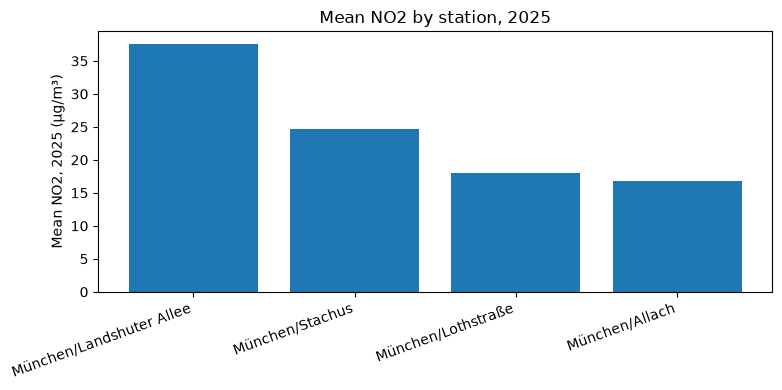

In [166]:
import os
import matplotlib.pyplot as plt

os.makedirs("figures", exist_ok=True)

no2_means = res1[res1["pollutant"] == "NO2"]
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(no2_means["name"], no2_means["mean_value"])
ax.set_ylabel("Mean NO2, 2025 (µg/m³)")
ax.set_title("Mean NO2 by station, 2025")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.savefig("figures/01_no2_by_station.png", dpi=150)
plt.show()

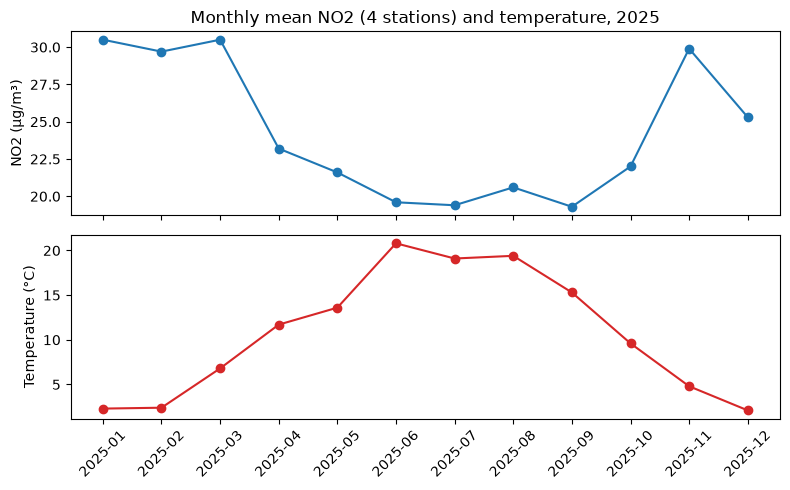

In [167]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(8, 5), sharex=True)
ax1.plot(res2["month"], res2["mean_no2"], marker="o")
ax1.set_ylabel("NO2 (µg/m³)")
ax1.set_title("Monthly mean NO2 (4 stations) and temperature, 2025")
ax2.plot(res2["month"], res2["mean_temp"], marker="o", color="tab:red")
ax2.set_ylabel("Temperature (°C)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("figures/02_monthly_no2_temperature.png", dpi=150)
plt.show()

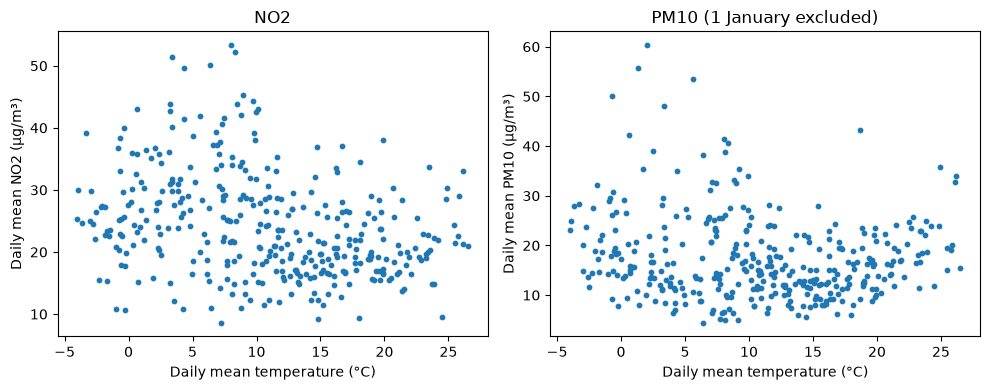

-0.3
-0.15


In [168]:
no2_d = daily[daily["pollutant"] == "NO2"].dropna()
pm_d = daily[(daily["pollutant"] == "PM10") & (daily["day"] != "2025-01-01")].dropna()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))
ax1.scatter(no2_d["mean_temp"], no2_d["mean_value"], s=10)
ax1.set_xlabel("Daily mean temperature (°C)")
ax1.set_ylabel("Daily mean NO2 (µg/m³)")
ax1.set_title("NO2")
ax2.scatter(pm_d["mean_temp"], pm_d["mean_value"], s=10)
ax2.set_xlabel("Daily mean temperature (°C)")
ax2.set_ylabel("Daily mean PM10 (µg/m³)")
ax2.set_title("PM10 (1 January excluded)")
plt.tight_layout()
plt.savefig("figures/03_daily_vs_temperature.png", dpi=150)
plt.show()

print(round(no2_d["mean_temp"].corr(no2_d["mean_value"]), 2))
print(round(pm_d["mean_temp"].corr(pm_d["mean_value"]), 2))